                             model    MAE    RMSE    R2  n_test     features
0                  Naive (t+1 = t)  66.89  103.88  0.89     282     baseline
1  Linear Regression (with shocks)  75.36  105.31  0.89     282  with shocks
2    Linear Regression (no shocks)  67.12   98.79  0.90     282    no shocks
3      Random Forest (with shocks)  75.21  109.79  0.88     282  with shocks
4        Random Forest (no shocks)  77.38  111.24  0.87     282    no shocks
5            XGBoost (with shocks)  87.34  122.64  0.85     282  with shocks
6              XGBoost (no shocks)  79.95  120.31  0.85     282    no shocks


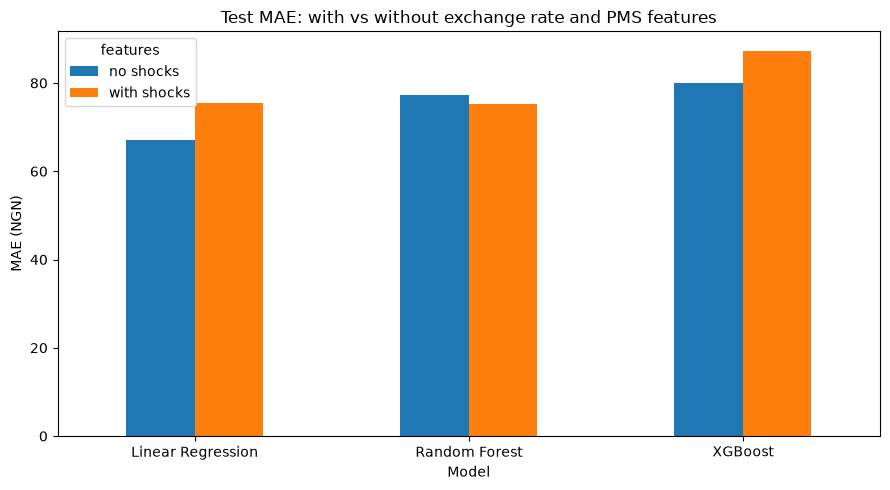

In [5]:
import os
import sys
import pathlib
import re

# Anchor working directory to the project root so relative paths stay consistent
for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents[:3]]:
    if (p / "src" / "evaluation.py").exists():
        os.chdir(p)
        if str(p) not in sys.path:
            sys.path.insert(0, str(p))
        break

import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from src.evaluation import get_features, run_experiment, naive_benchmark

df = pd.read_csv("data/processed/master.csv", parse_dates=["month"])

rows = []
for shock in [True, False]:
    model = XGBRegressor(
        n_estimators=300, learning_rate=0.05, max_depth=4, random_state=42
    )
    rows.append(run_experiment(df, model, get_features(df, shock), "XGBoost"))
xgb = pd.DataFrame(rows)
xgb.to_csv("reports/results_xgb.csv", index=False)

lr_rf = pd.read_csv("reports/results_lr_rf.csv")
all_results = pd.concat(
    [lr_rf, xgb, pd.DataFrame([naive_benchmark(df)])], ignore_index=True
)

# Normalize `features` column and remove duplicate baseline rows
if "shock_features" in all_results.columns:
    mapped = all_results["shock_features"].map(
        {True: "with shocks", False: "no shocks"}
    )
    all_results["features"] = all_results["features"].fillna(mapped)
    all_results.loc[
        all_results["model"].str.startswith("Naive") & all_results["features"].isna(),
        "features",
    ] = "baseline"
    all_results = all_results.drop(columns=["shock_features"])

all_results = (
    all_results.drop_duplicates(subset=["model", "features"], keep="first")
    .reset_index(drop=True)
)
print(all_results.round(2))
all_results.to_csv("reports/results_all_models.csv", index=False)

# Grouped bar chart: side-by-side "no shocks" vs "with shocks" for each model
model_df = all_results[all_results["features"].isin(["with shocks", "no shocks"])].copy()
model_df["base_model"] = model_df["model"].apply(
    lambda s: re.sub(r"\s*\((with shocks|no shocks)\)$", "", s)
)

pivot_mae = model_df.pivot(index="base_model", columns="features", values="MAE")[
    ["no shocks", "with shocks"]
]
ax = pivot_mae.plot.bar(
    figsize=(9, 5),
    title="Test MAE: with vs without exchange rate and PMS features",
)
ax.set_xlabel("Model")
ax.set_ylabel("MAE (NGN)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("reports/figures/model_comparison_mae.png", dpi=200, bbox_inches="tight")
plt.show()